<a href="https://colab.research.google.com/github/gayathridevies-arch/QSPR-LogS-Predictor-Machine-Learning-for-Molecular-Solubility/blob/main/QSPR_LogS_Predictor_Machine_Learning_for_Molecular_Solubility.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 59.4 MB/s eta 0:00:00
Model R2 score: 0.698
Mean Absolute Error: 0.86


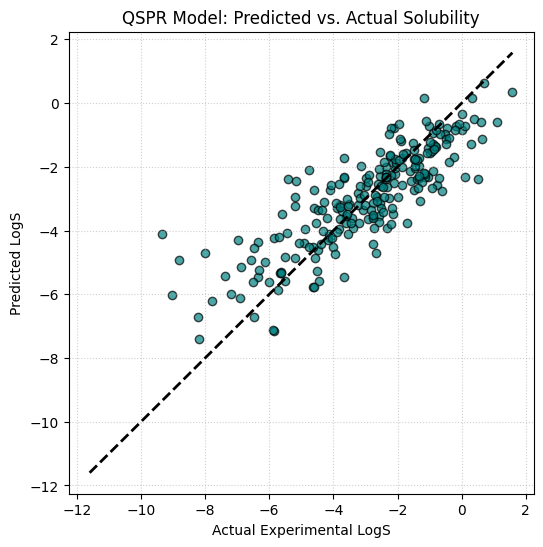

In [1]:
!pip install rdkit
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import AllChem,rdFingerprintGenerator
from rdkit import DataStructs
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,r2_score
from sklearn.model_selection import train_test_split
df=pd.read_csv("https://raw.githubusercontent.com/dataprofessor/data/master/delaney.csv")
df.head(2)
df["Mol"]=df["SMILES"].apply(Chem.MolFromSmiles)
def get_fingerprint(mol):
  mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
  fp = mfpgen.GetFingerprint(mol)
  arr=np.zeros((1,))
  DataStructs.ConvertToNumpyArray(fp,arr)
  return arr
X=np.array([get_fingerprint(m)for m in df["Mol"]])
y=df["measured log(solubility:mol/L)"].values
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
model=RandomForestRegressor(n_estimators=100,random_state=42)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
r2=r2_score(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
print("Model R2 score:",round(r2,3))
print("Mean Absolute Error:",round(mae,3))
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, color="teal", alpha=0.7, edgecolors="k")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "k--", lw=2)
plt.xlabel("Actual Experimental LogS")
plt.ylabel("Predicted LogS")
plt.title("QSPR Model: Predicted vs. Actual Solubility")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()
